In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 넘파이 배열 파일 불러오기
loaded_arr = np.load("shapes_data.npy")

# 형태(shape) 확인
print(loaded_arr.shape)  # 출력: (60, 100, 100) -> 60개의 100픽셀 x 100픽셀 이미지 데이터
print(len(loaded_arr)) 

(60, 100, 100)
60


In [2]:
print(loaded_arr[0]) # 0~29 실제이미지 네모
display(loaded_arr[0])
print(loaded_arr[30]) # 30~59 실제이미지 세모
display(loaded_arr[30])

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(100, 100), dtype=uint8)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(100, 100), dtype=uint8)

In [8]:
import numpy as np
np.set_printoptions(threshold=np.inf)
print(loaded_arr[0]) 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0 

In [9]:
np.set_printoptions(threshold=1000)

In [5]:
# 2. K-Means 군집화 수행
count = loaded_arr.shape[0] # 60

# fit() 매개값은 2차원 데이터
# reshape : 60 x 100 x 100 3차원데이터를  60 x (100x100) -> 60 x 10000 의 2차원으로 변경 
# X = loaded_arr.reshape(count, 10000)
X = loaded_arr.reshape(count, -1) 
# -1은 남은 차원값을 알아서 계산해서 넣음 count가 60이니, 100, 100인 자동계산 후 10000으로 입력

kmeans = KMeans(n_clusters=2, random_state=1) # 2개로 클러스터(군집)

# kmeans = KMeans(n_clusters=3, random_state=1) 
# 데이터를 3개로 클러스터, 세모클래스 비슷한데, 네모클래스가 두클래스로 클러스터됨 

cluster = kmeans.fit_predict # 학습 후 결과 반환
# 아래와 동일한 코드
# kmeans.fit(X) # 학습
# cluster = kmeans.labels_ # 결과 저장

print(cluster) # 정답이 없는 데이터를 2개로 분류하라고 했으니 데이터에 특성에 따라 0, 1로 분류

<bound method _BaseKMeans.fit_predict of KMeans(n_clusters=2, random_state=1)>


In [10]:
# 2. 60행 1열 서브플롯 생성 (아래로 쭉 길게 출력)
fig, axes = plt.subplots(60, 1, figsize=(100, 100))

# 3. 반복문을 돌며 이미지 출력, 총 60개의 차트(이미지)
for i in range(60):
    ax = axes[i]  # 1차원 인덱스 직접 사용
    ax.imshow(loaded_arr[i])
    
    # 군집 번호 (0 또는 1)
    c = cluster_labels[i]
    color = "red" if c == 0 else "blue"
    
    # 제목에 간단히 번호와 0 또는 1만 표기
    ax.set_title(f'index{i} result {c}' ,color=color) # 제목에 cluster_labels 출력, 0은 빨간색으로 출려그, 1은 파란색으로 출력
    ax.axis("off") # x,y 좌표 숨기기

plt.tight_layout()
plt.show()

NameError: name 'cluster_labels' is not defined

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


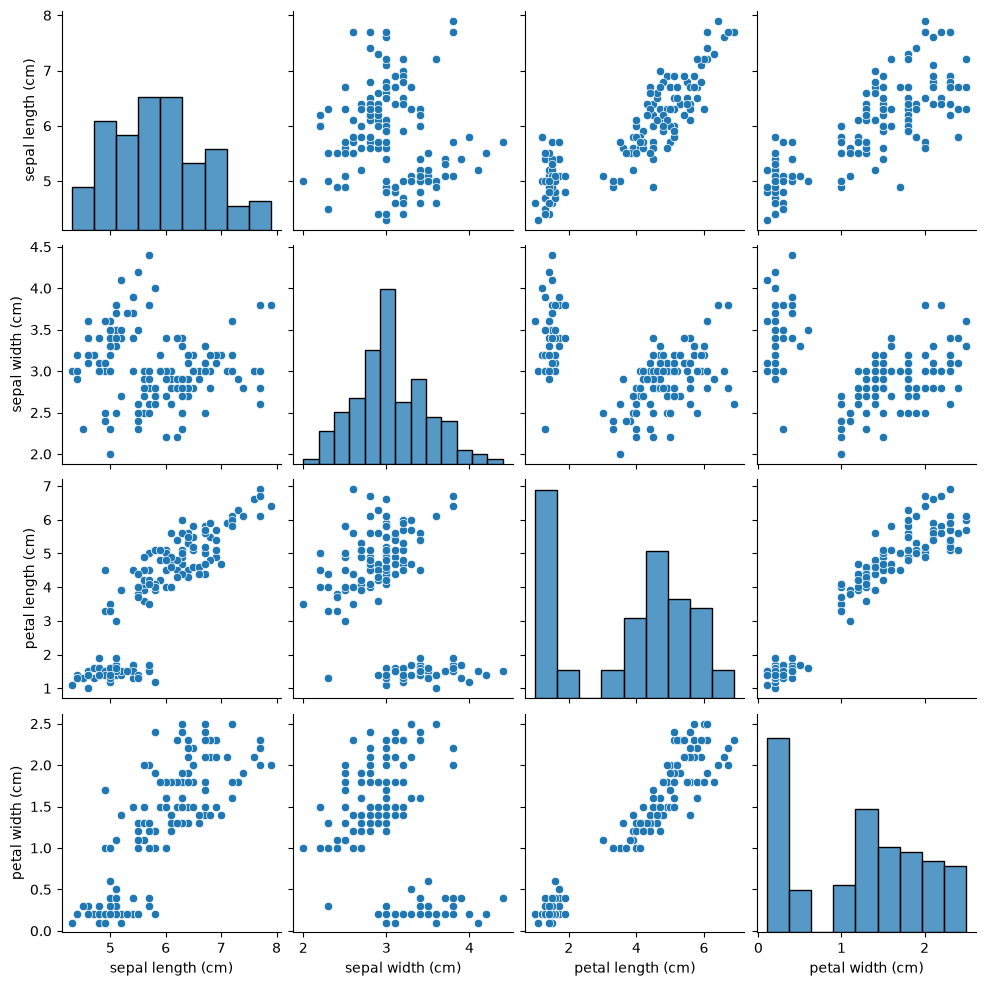

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. 데이터 로드
# as_frame=True numpy배열타입이 아닌 판다스(데이터프레임, 시리즈)타입으로 반환
# pairplot()dm으로 산점도 행열을 출력하려면 데이터프레임 타입이 필요
iris = load_iris(as_frame=True) 
X = iris.data  # 정답 특성 target 제외

display(X.head())

# 2. 산점도로 데이터 분포 탐색
sns.pairplot(X)

# 3. 표준화: Z-score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. K-means 군집 학습
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster = kmeans.fit_predict(X_scaled)

In [13]:
# 5. 원본 데이터 + 군집 결과 + 실제 정답 비교
print(cluster)
print(type(iris.target))
# 시리즈 타입이라 비교가 힘들어 넘파이 배열로 변경 후 출력 0, 1, 2값은 다룰 수 있음. 군집을 비교
print(iris.target.to_numpy()) 

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
<class 'pandas.Series'>
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
